# Category Lifecycle & Opportunity Analysis

## Project Overview

This notebook examines historical product category performance using the Brazilian Olist e-commerce dataset.

The analysis focuses on category-level performance, feature engineering, and K-Means clustering to identify distinct patterns in category scale, activity, and commercial opportunity.

## Analytical Objectives

- Prepare and validate category-level data.
- Engineer features to describe category performance and lifecycle patterns.
- Apply K-Means clustering to segment product categories.
- Interpret cluster characteristics and commercial opportunities.

## Tools & Methods

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Feature Engineering
- K-Means Clustering

**Dataset coverage:** September 2016 to October 2018 (25 months).

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
base_url = "https://raw.githubusercontent.com/joleighshipman/analytics-portfolio/main/project-03-category-lifecycle/data/"

opportunity_scores = pd.read_csv(
    base_url + "project3_opportunity_scores.csv"
)

monthly_sales = pd.read_csv(
    base_url + "project3_monthly_sales.csv"
)

print("Opportunity Scores:", opportunity_scores.shape)
print("Monthly Sales:", monthly_sales.shape)

Opportunity Scores: (71, 8)
Monthly Sales: (1253, 5)


In [3]:
from google.colab import files

uploaded = files.upload()

Saving project3_monthly_sales.csv to project3_monthly_sales (2).csv
Saving project3_opportunity_scores.csv to project3_opportunity_scores (2).csv


In [4]:
base_url = "https://raw.githubusercontent.com/joleighshipman/analytics-portfolio/main/project-03-category-lifecycle/data/"

opportunity_scores = pd.read_csv(
    base_url + "project3_opportunity_scores.csv"
)

monthly_sales = pd.read_csv(
    base_url + "project3_monthly_sales.csv"
)

print("Opportunity Scores:", opportunity_scores.shape)
print("Monthly Sales:", monthly_sales.shape)

Opportunity Scores: (71, 8)
Monthly Sales: (1253, 5)


In [5]:
with open('/content/project3_opportunity_scores.csv', 'r', encoding='utf-8-sig') as file:
    for i in range(8):
        print(repr(file.readline()))

'category,total_revenue,total_orders,active_months,activity_month_pct,growth_consistency_pct,opportunity_score,opportunity_class\n'
'health_beauty,1258681.34,8836,22,88.0,75.0,3,High Opportunity\n'
'housewares,632248.66,5884,21,84.0,63.16,3,High Opportunity\n'
'auto,592720.11,3897,21,84.0,73.68,3,High Opportunity\n'
'perfumery,399124.87,3162,21,84.0,68.42,3,High Opportunity\n'
'telephony,323667.53,4199,22,88.0,75.0,3,High Opportunity\n'
'pet_shop,214315.41,1710,21,84.0,63.16,3,High Opportunity\n'
'watches_gifts,1205005.68,5624,21,84.0,57.89,2,Moderate Opportunity\n'


In [6]:
with open('/content/project3_monthly_sales.csv', 'r', encoding='utf-8-sig') as file:
    for i in range(8):
        print(repr(file.readline()))

'month,category,total_orders,total_revenue,units_sold\n'
'2017-01,agro_industry_and_commerce,2,65.97,3\n'
'2017-02,agro_industry_and_commerce,7,224.84,7\n'
'2017-03,agro_industry_and_commerce,2,81.99,2\n'
'2017-05,agro_industry_and_commerce,4,1579.94,4\n'
'2017-06,agro_industry_and_commerce,1,1390.0,1\n'
'2017-07,agro_industry_and_commerce,1,1180.0,1\n'
'2017-08,agro_industry_and_commerce,1,88.0,4\n'


In [7]:
opportunity_scores = pd.read_csv('/content/project3_opportunity_scores.csv')
monthly_sales = pd.read_csv('/content/project3_monthly_sales.csv')

print("Opportunity Scores:", opportunity_scores.shape)
print("Monthly Sales:", monthly_sales.shape)

display(opportunity_scores.head())
display(monthly_sales.head())

Opportunity Scores: (71, 8)
Monthly Sales: (1253, 5)


,category,total_revenue,total_orders,active_months,activity_month_pct,growth_consistency_pct,opportunity_score,opportunity_class
0,health_beauty,"1,258,681.34",8836,22,88.00,75.00,3,High Opportunity
1,housewares,"632,248.66",5884,21,84.00,63.16,3,High Opportunity
2,auto,"592,720.11",3897,21,84.00,73.68,3,High Opportunity
3,perfumery,"399,124.87",3162,21,84.00,68.42,3,High Opportunity
4,telephony,"323,667.53",4199,22,88.00,75.00,3,High Opportunity


,month,category,total_orders,total_revenue,units_sold
0,2017-01,agro_industry_and_commerce,2,65.97,3
1,2017-02,agro_industry_and_commerce,7,224.84,7
2,2017-03,agro_industry_and_commerce,2,81.99,2
3,2017-05,agro_industry_and_commerce,4,"1,579.94",4
4,2017-06,agro_industry_and_commerce,1,"1,390.00",1


In [8]:
print("OPPORTUNITY SCORES")
opportunity_scores.info()

print("\nMONTHLY SALES")
monthly_sales.info()

OPPORTUNITY SCORES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   category                71 non-null     object 
 1   total_revenue           71 non-null     float64
 2   total_orders            71 non-null     int64  
 3   active_months           71 non-null     int64  
 4   activity_month_pct      71 non-null     float64
 5   growth_consistency_pct  70 non-null     float64
 6   opportunity_score       71 non-null     int64  
 7   opportunity_class       71 non-null     object 
dtypes: float64(3), int64(3), object(2)
memory usage: 4.6+ KB

MONTHLY SALES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1253 entries, 0 to 1252
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   month          1253 non-null   object 
 1   category       1253 non-null 

In [9]:
opportunity_scores[
    opportunity_scores['growth_consistency_pct'].isna()
]

,category,total_revenue,total_orders,active_months,activity_month_pct,growth_consistency_pct,opportunity_score,opportunity_class
70,security_and_services,283.29,2,2,8.00,NaN,0,Low Opportunity


In [10]:
print("Missing values by column:")
print(opportunity_scores.isna().sum())

print("\nCategory count:")
print(opportunity_scores['category'].nunique())

print("\nOpportunity class distribution:")
print(opportunity_scores['opportunity_class'].value_counts())

Missing values by column:
category                  0
total_revenue             0
total_orders              0
active_months             0
activity_month_pct        0
growth_consistency_pct    1
opportunity_score         0
opportunity_class         0
dtype: int64

Category count:
71

Opportunity class distribution:
opportunity_class
Limited Opportunity     30
Low Opportunity         21
Moderate Opportunity    14
High Opportunity         6
Name: count, dtype: int64


In [11]:
opportunity_scores[
    [
        'total_revenue',
        'total_orders',
        'active_months',
        'activity_month_pct',
        'growth_consistency_pct'
    ]
].describe().round(2)

,total_revenue,total_orders,active_months,activity_month_pct,growth_consistency_pct
count,71.00,71.00,71.00,71.00,70.00
mean,"188,825.27","1,380.24",17.65,70.59,54.00
std,"303,705.20","2,272.86",4.58,18.33,12.69
min,283.29,2.00,2.00,8.00,25.00
25%,"9,171.18",87.00,15.00,60.00,45.85
50%,"46,856.88",248.00,20.00,80.00,52.63
75%,"202,907.14","1,491.50",21.00,84.00,61.16
max,"1,258,681.34","9,417.00",22.00,88.00,100.00


In [12]:
clustering_features = opportunity_scores[
    [
        'total_revenue',
        'total_orders',
        'active_months',
        'activity_month_pct',
        'growth_consistency_pct'
    ]
].copy()

clustering_features = clustering_features.dropna()

print("Original categories:", len(opportunity_scores))
print("Categories ready for clustering:", len(clustering_features))
print("Excluded categories:", len(opportunity_scores) - len(clustering_features))

Original categories: 71
Categories ready for clustering: 70
Excluded categories: 1


In [13]:
scaler = StandardScaler()

scaled_features = scaler.fit_transform(clustering_features)

print("Scaled data shape:", scaled_features.shape)
print("Feature means:", scaled_features.mean(axis=0).round(2))
print("Feature standard deviations:", scaled_features.std(axis=0).round(2))

Scaled data shape: (70, 5)
Feature means: [0. 0. 0. 0. 0.]
Feature standard deviations: [1. 1. 1. 1. 1.]


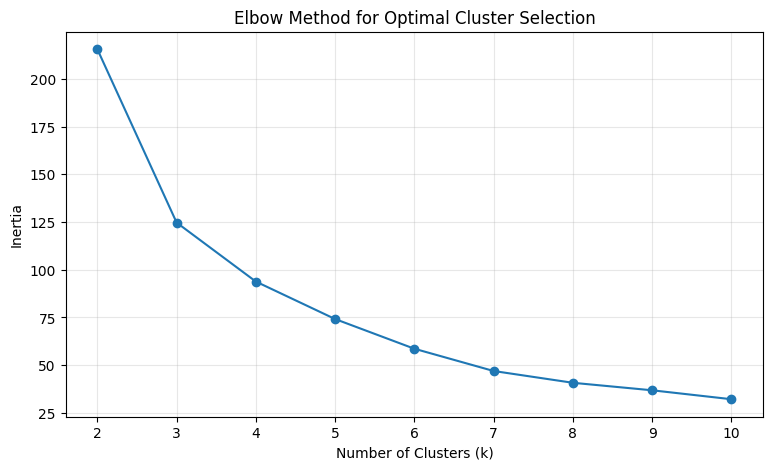

In [14]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(range(2, 11), inertia, marker='o')
plt.title('Elbow Method for Optimal Cluster Selection')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(range(2, 11))
plt.grid(True, alpha=0.3)
plt.show()

In [15]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(scaled_features)
    score = silhouette_score(scaled_features, labels)

    silhouette_scores.append(score)

    print(f"k={k}: {score:.3f}")

k=2: 0.443
k=3: 0.442
k=4: 0.453
k=5: 0.427
k=6: 0.420
k=7: 0.380
k=8: 0.364
k=9: 0.362
k=10: 0.334


In [16]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clustering_features['cluster'] = kmeans.fit_predict(scaled_features)

print("Cluster assignments:")
print(clustering_features['cluster'].value_counts().sort_index())

Cluster assignments:
cluster
0    36
1     9
2    13
3    12
Name: count, dtype: int64


In [17]:
cluster_profiles = clustering_features.groupby('cluster').mean().round(2)

display(cluster_profiles)

,total_revenue,total_orders,active_months,activity_month_pct,growth_consistency_pct
cluster,,,,,
0,"87,839.10",639.08,19.86,79.44,51.67
1,"26,262.28",40.00,10.44,41.78,36.81
2,"744,822.81","5,608.69",21.23,84.92,60.30
3,"27,087.16",142.92,13.83,55.33,67.05


In [18]:
cluster_results = opportunity_scores.loc[
    clustering_features.index,
    ['category', 'opportunity_class']
].copy()

cluster_results['cluster'] = clustering_features['cluster']

display(
    cluster_results.sort_values(
        ['cluster', 'category']
    )
)

,category,opportunity_class,cluster
50,agro_industry_and_commerce,Low Opportunity,0
30,air_conditioning,Limited Opportunity,0
54,art,Low Opportunity,0
31,audio,Limited Opportunity,0
14,baby,Moderate Opportunity,0
...,...,...,...
42,costruction_tools_tools,Limited Opportunity,3
48,fashio_female_clothing,Limited Opportunity,3
47,furniture_mattress_and_upholstery,Limited Opportunity,3
61,music,Low Opportunity,3


In [19]:
for cluster_number in sorted(cluster_results['cluster'].unique()):
    categories = cluster_results.loc[
        cluster_results['cluster'] == cluster_number,
        'category'
    ].tolist()

    print(f"\nCLUSTER {cluster_number} ({len(categories)} categories)")
    print(", ".join(categories))


CLUSTER 0 (36 categories)
pet_shop, baby, office_furniture, stationery, musical_instruments, small_appliances, fixed_telephony, electronics, consoles_games, fashion_bags_accessories, luggage_accessories, home_appliances_2, home_construction, home_appliances, furniture_living_room, air_conditioning, audio, books_general_interest, kitchen_dining_laundry_garden_furniture, food, market_place, fashion_shoes, furniture_bedroom, books_technical, fashion_male_clothing, fashion_underwear_beach, dvds_blu_ray, agro_industry_and_commerce, home_confort, industry_commerce_and_business, costruction_tools_garden, art, drinks, signaling_and_security, food_drink, tablets_printing_image

CLUSTER 1 (9 categories)
computers, party_supplies, fashion_sport, la_cuisine, diapers_and_hygiene, flowers, home_comfort_2, cds_dvds_musicals, fashion_childrens_clothes

CLUSTER 2 (13 categories)
health_beauty, housewares, auto, perfumery, telephony, watches_gifts, bed_bath_table, sports_leisure, computers_accessories,

In [20]:
cluster_comparison = pd.crosstab(
    cluster_results['cluster'],
    cluster_results['opportunity_class']
)

display(cluster_comparison)

opportunity_class,High Opportunity,Limited Opportunity,Low Opportunity,Moderate Opportunity
cluster,,,,
0,1,20,9,6
1,0,1,8,0
2,5,0,0,8
3,0,9,3,0


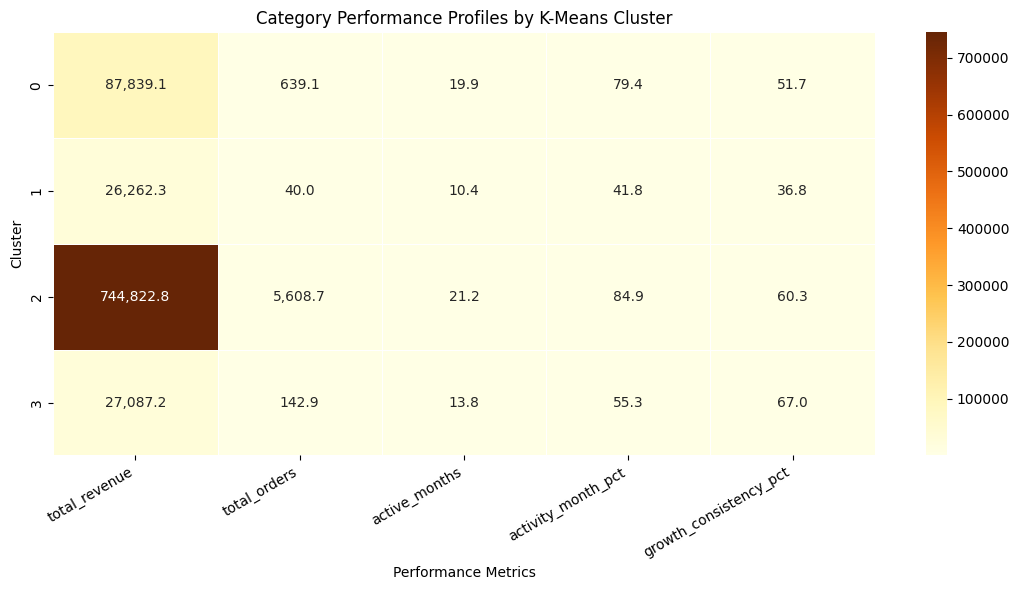

In [21]:
plt.figure(figsize=(11, 6))

sns.heatmap(
    cluster_profiles,
    annot=True,
    fmt=',.1f',
    cmap='YlOrBr',
    linewidths=0.5
)

plt.title('Category Performance Profiles by K-Means Cluster')
plt.xlabel('Performance Metrics')
plt.ylabel('Cluster')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [22]:
cluster_results.to_csv(
    'project3_kmeans_cluster_assignments.csv',
    index=False
)

cluster_profiles.to_csv(
    'project3_kmeans_cluster_profiles.csv'
)

print("Cluster assignments and profiles exported successfully.")

Cluster assignments and profiles exported successfully.


In [23]:
from google.colab import files

files.download('project3_kmeans_cluster_assignments.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
files.download('project3_kmeans_cluster_profiles.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

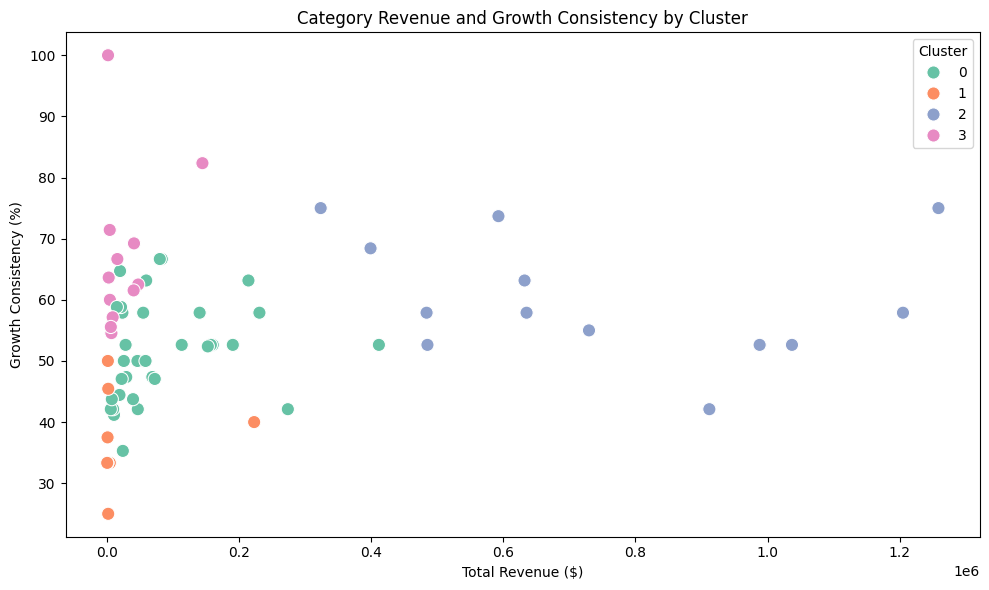

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clustering_features,
    x='total_revenue',
    y='growth_consistency_pct',
    hue='cluster',
    palette='Set2',
    s=90
)

plt.title('Category Revenue and Growth Consistency by Cluster')
plt.xlabel('Total Revenue ($)')
plt.ylabel('Growth Consistency (%)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

In [26]:
plt.savefig(
    'project3_kmeans_revenue_growth_clusters.png',
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

In [27]:
from google.colab import files
files.download('project3_kmeans_revenue_growth_clusters.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

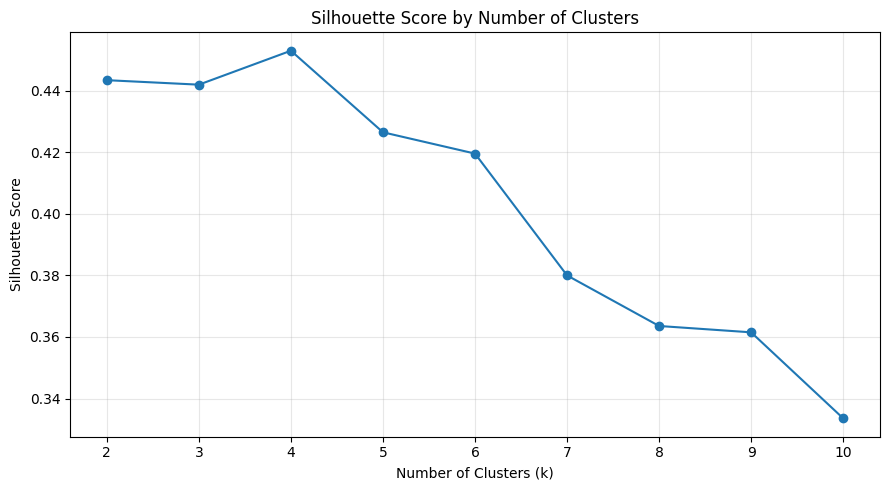

In [28]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Score by Number of Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    'project3_silhouette_scores.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [29]:
from google.colab import files
files.download('project3_silhouette_scores.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

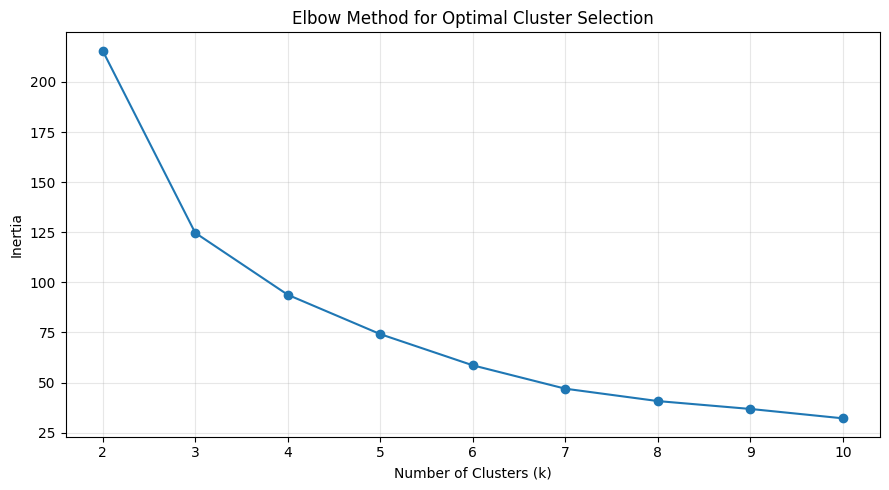

In [30]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.title('Elbow Method for Optimal Cluster Selection')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(range(2, 11))
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    'project3_elbow_method.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [31]:
from google.colab import files
files.download('project3_elbow_method.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Clustering Methodology

### Data Preparation

The category-level opportunity dataset contained 71 product categories. One category, security_and_services, was excluded from clustering because its growth consistency metric was undefined.

The remaining 70 categories were evaluated using five numerical features:

- Total revenue
- Total orders
- Active months
- Activity month percentage
- Growth consistency percentage

### Feature Scaling

StandardScaler was applied to standardize the five numerical features before K-Means clustering.

### Cluster Selection

The Elbow Method and silhouette scores were evaluated for cluster counts ranging from 2 to 10.

Four clusters produced the highest silhouette score of 0.453 among the tested configurations and were selected for further interpretation.

### Clustering Model

K-Means was fitted using four clusters, random_state=42, and n_init=10.

### Interpretation

Cluster profiles were examined to compare category revenue, order volume, activity, and growth consistency. Cluster assignments were also compared with the SQL-based opportunity classifications to identify areas of agreement and difference.

## Key Findings

### Cluster 0: Established, Moderate-Scale Categories

This was the largest segment, containing 36 categories. These categories demonstrated relatively high activity across the observation period, with moderate average revenue and order volume.

### Cluster 1: Lower-Activity Categories

This segment contained 9 categories and demonstrated the lowest average order volume, active months, and growth consistency.

### Cluster 2: High-Scale Categories

This segment contained 13 categories and generated the highest average revenue and order volume. All categories in this cluster received either High or Moderate Opportunity classifications under the SQL scoring framework.

### Cluster 3: Smaller-Scale Categories with Higher Growth Consistency

This segment contained 12 categories. Although average revenue and order volume were relatively low, this group demonstrated the highest average growth consistency.

### Business Implications

The results distinguish categories with established commercial scale from those with lower activity or comparatively consistent historical revenue increases.

Combining SQL-based opportunity scoring with unsupervised clustering provides two complementary perspectives on category performance. These findings can help prioritize further investigation into category positioning, assortment strategy, and commercial opportunities.

**Analytical limitation:** The findings describe historical performance within the dataset. They do not establish future demand or guarantee future commercial growth.

## Model Evaluation Results

### Silhouette Score Comparison

| Number of Clusters | Silhouette Score |
|---:|---:|
| 2 | 0.443 |
| 3 | 0.442 |
| 4 | 0.453 |
| 5 | 0.427 |
| 6 | 0.420 |
| 7 | 0.380 |
| 8 | 0.364 |
| 9 | 0.362 |
| 10 | 0.334 |

The four-cluster solution achieved the highest silhouette score among the tested configurations.

### Final Cluster Distribution

| Cluster | Number of Categories |
|---:|---:|
| 0 | 36 |
| 1 | 9 |
| 2 | 13 |
| 3 | 12 |
| **Total** | **70** |

Cluster 2 demonstrated the strongest average commercial scale, while Cluster 1 contained the lowest-activity categories.